# Audio Pipeline & Voiceprint Verification Model (Part C)

## 1. Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q librosa soundfile

BASE      = '/content/drive/MyDrive/Formative 2 ML_pipeline_Data_Collection'
AUDIO_DIR = f'{BASE}/audio'
OUT_DIR   = f'{BASE}/outputs'

Mounted at /content/drive


## 2. Imports

In [ ]:
%matplotlib inline
import argparse
import glob
import os

import librosa
import librosa.display
import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

SR = 16000
N_MFCC = 13
RNG = np.random.default_rng(42)

## 3. Load pipeline

In [ ]:
def load_audio(path, sr=SR, trim=True):
    """Load as mono at a fixed sample rate and trim leading/trailing silence."""
    y, _ = librosa.load(path, sr=sr, mono=True)
    if trim:
        trimmed, _ = librosa.effects.trim(y, top_db=25)
        if len(trimmed) > sr * 0.2: 
            y = trimmed
    return y


def discover_samples(audio_dir):
    """Return a list of dicts: member, phrase, recording_id, path."""
    rows = []
    for path in sorted(glob.glob(os.path.join(audio_dir, "*", "*.*"))):
        if not path.lower().endswith((".wav", ".mp3", ".flac", ".m4a", ".ogg")):
            continue
        member = os.path.basename(os.path.dirname(path)).lower()
        stem = os.path.splitext(os.path.basename(path))[0].lower()
        phrase = "_".join(p for p in stem.split("_") if not p.isdigit() and p != member) or stem
        rows.append({"member": member, "phrase": phrase,
                     "recording_id": f"{member}/{stem}", "path": path})
    if not rows:
        raise FileNotFoundError(f"No audio files found under {audio_dir}/<member>/")
    return rows

## 4. Pipeline: Visualization

In [ ]:
def plot_waveform_spectrogram(y, title, save_path=None, sr=SR):
    """Waveform (top) + log-mel spectrogram (bottom) for one sample."""
    fig, ax = plt.subplots(2, 1, figsize=(9, 5))
    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set(title=f"Waveform - {title}", xlabel="Time (s)", ylabel="Amplitude")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64), ref=np.max)
    img = librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel", ax=ax[1])
    ax[1].set(title=f"Mel spectrogram - {title}")
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120)
        plt.close(fig)
    return fig


def plot_augmentation_comparison(y, augmented, title, save_path=None, sr=SR):
    """Original vs each augmentation: one row each, waveform on the left, spectrogram right."""
    items = [("original", y)] + list(augmented.items())
    fig, axes = plt.subplots(len(items), 2, figsize=(11, 2.2 * len(items)))
    for i, (name, sig) in enumerate(items):
        librosa.display.waveshow(sig, sr=sr, ax=axes[i, 0])
        axes[i, 0].set_title(f"{name} (waveform)", fontsize=9)
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=sig, sr=sr, n_mels=64), ref=np.max)
        librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel", ax=axes[i, 1])
        axes[i, 1].set_title(f"{name} (spectrogram)", fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110)
        plt.close(fig)
    return fig

## 5. Pipeline: Augmentations per sample

In [ ]:
def time_stretch(y, rate=1.1):
    return librosa.effects.time_stretch(y, rate=rate)


def add_noise(y, snr_db=20):
    """Add white noise at a given signal-to-noise ratio."""
    sig_power = np.mean(y ** 2) + 1e-12
    noise_power = sig_power / (10 ** (snr_db / 10))
    return y + RNG.normal(0, np.sqrt(noise_power), size=y.shape)


def augment_all(y, sr=SR):
    return {
        "time_stretch": time_stretch(y, 1.1),   
        "noise": add_noise(y, 20),              
    }

## 6. Pipeline: Feature Extraction

In [ ]:
def extract_features(y, sr=SR):
    """Fixed-length feature vector: MFCC (mean/std), spectral roll-off, energy, + a few extras."""
    feats = {}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    for i in range(N_MFCC):
        feats[f"mfcc_{i + 1}_mean"] = float(np.mean(mfcc[i]))
        feats[f"mfcc_{i + 1}_std"] = float(np.std(mfcc[i]))

    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)[0]
    rms = librosa.feature.rms(y=y)[0]
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]

    feats.update({
        "rolloff_mean": float(np.mean(rolloff)), "rolloff_std": float(np.std(rolloff)),
        "rms_mean": float(np.mean(rms)), "rms_std": float(np.std(rms)),
        "energy_total": float(np.sum(y ** 2)),
        "centroid_mean": float(np.mean(centroid)),
        "bandwidth_mean": float(np.mean(bandwidth)),
        "zcr_mean": float(np.mean(zcr)),
        "duration_s": float(len(y) / sr),
    })
    return feats


FEATURE_PREFIXES = ("mfcc_", "rolloff_", "rms_", "energy_", "centroid_", "bandwidth_", "zcr_", "duration_")


def feature_columns(df):
    return [c for c in df.columns if c.startswith(FEATURE_PREFIXES)]

## 7. Run pipeline

In [ ]:
def run_pipeline(audio_dir, out_dir, save_augmented_wavs=True):
    plots_dir = os.path.join(out_dir, "audio_plots")
    aug_dir = os.path.join(out_dir, "augmented_audio")
    os.makedirs(plots_dir, exist_ok=True)
    os.makedirs(aug_dir, exist_ok=True)

    samples = discover_samples(audio_dir)
    print(f"Found {len(samples)} recordings from {len({s['member'] for s in samples})} member(s)")

    rows = []
    for s in samples:
        y = load_audio(s["path"])
        tag = s["recording_id"].replace("/", "_")

        plot_waveform_spectrogram(y, s["recording_id"], os.path.join(plots_dir, f"{tag}_original.png"))

        augmented = augment_all(y)
        plot_augmentation_comparison(y, augmented, s["recording_id"],
                                     os.path.join(plots_dir, f"{tag}_augmentations.png"))

        variants = {"original": y, **augmented}
        for aug_name, sig in variants.items():
            if save_augmented_wavs and aug_name != "original":
                sf.write(os.path.join(aug_dir, f"{tag}_{aug_name}.wav"), sig, SR)
            row = {"member": s["member"], "phrase": s["phrase"],
                   "recording_id": s["recording_id"], "augmentation": aug_name}
            row.update(extract_features(sig))
            rows.append(row)

    df = pd.DataFrame(rows)
    csv_path = os.path.join(out_dir, "audio_features.csv")
    df.to_csv(csv_path, index=False)
    print(f"Saved {len(df)} rows x {len(feature_columns(df))} features -> {csv_path}")
    return df

In [ ]:
import IPython.display as ipd
samples = discover_samples(AUDIO_DIR)
pd.DataFrame(samples)[['member', 'phrase', 'recording_id']]

,member,phrase,recording_id
0,david,approve,david/david_approve
1,david,confirm,david/david_confirm
2,faith,approve,faith/faith_approve
3,faith,confirm,faith/faith_confirm
4,honette,approve,honette/honette_approve
5,honette,confirm,honette/honette_confirm
6,steven,approve,steven/steven_approve
7,steven,confirm,steven/steven_confirm


## 8. Plot samples

/tmp/ipykernel_7869/1294308.py:25: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


david/david_approve


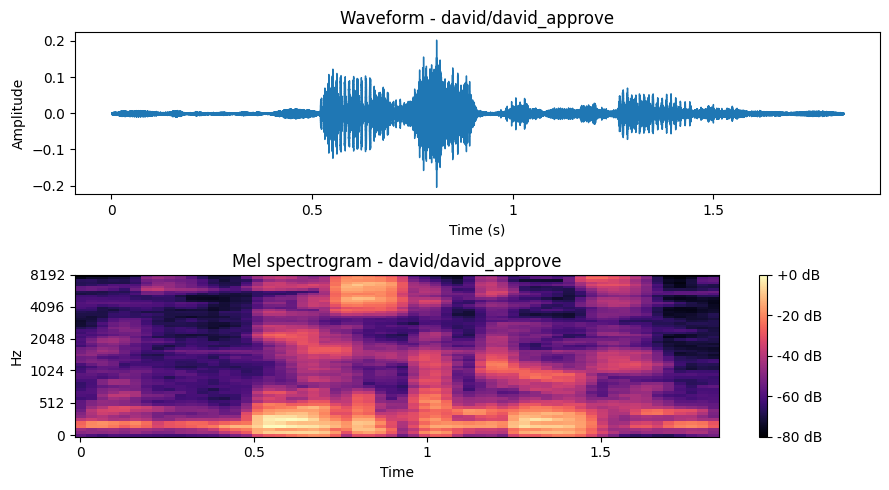

david/david_confirm


/tmp/ipykernel_7869/1294308.py:25: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


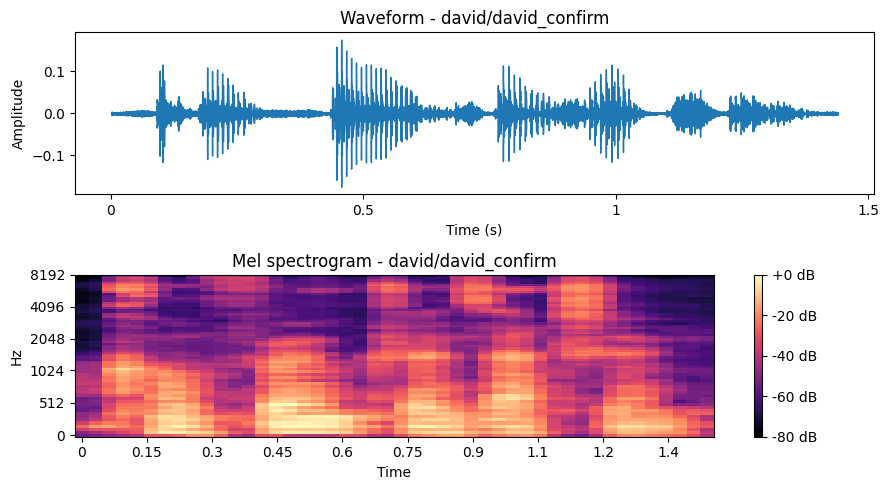

faith/faith_approve


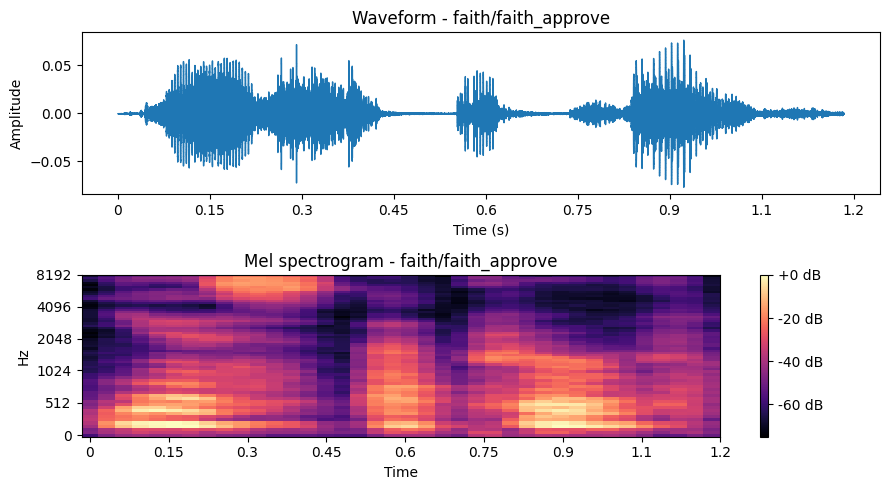

faith/faith_confirm


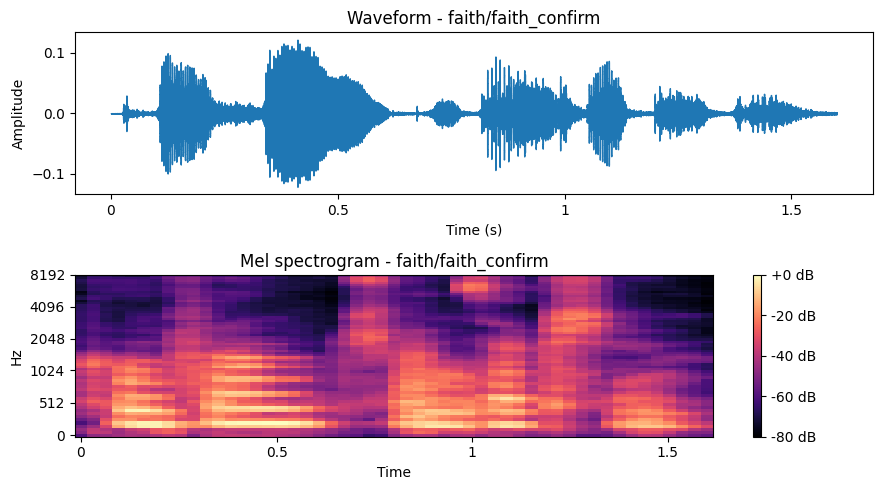

honette/honette_approve


/tmp/ipykernel_7869/1294308.py:25: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


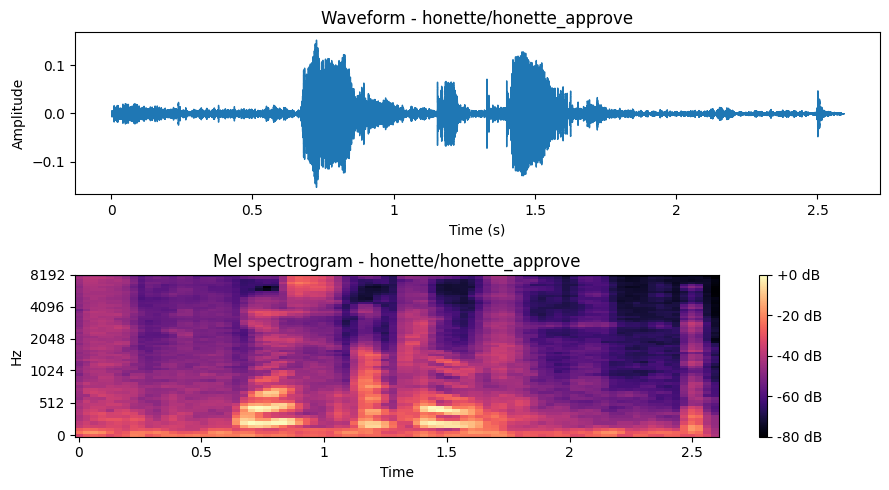

honette/honette_confirm


/tmp/ipykernel_7869/1294308.py:25: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


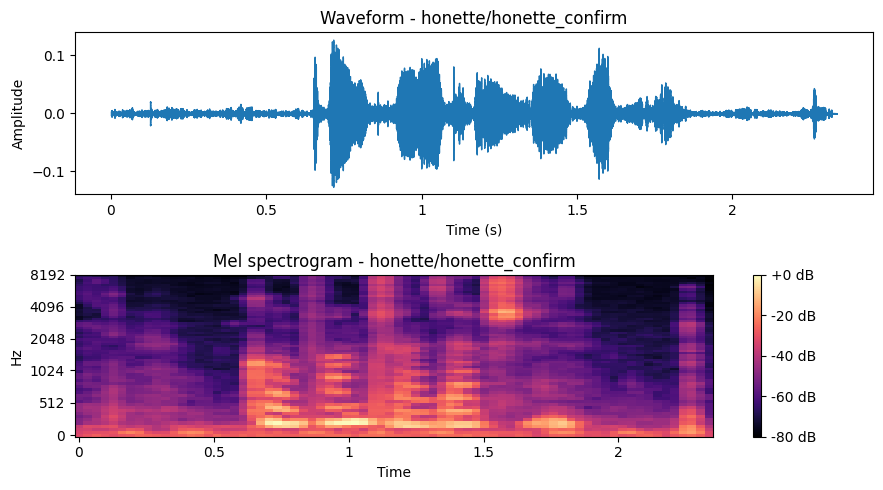

steven/steven_approve


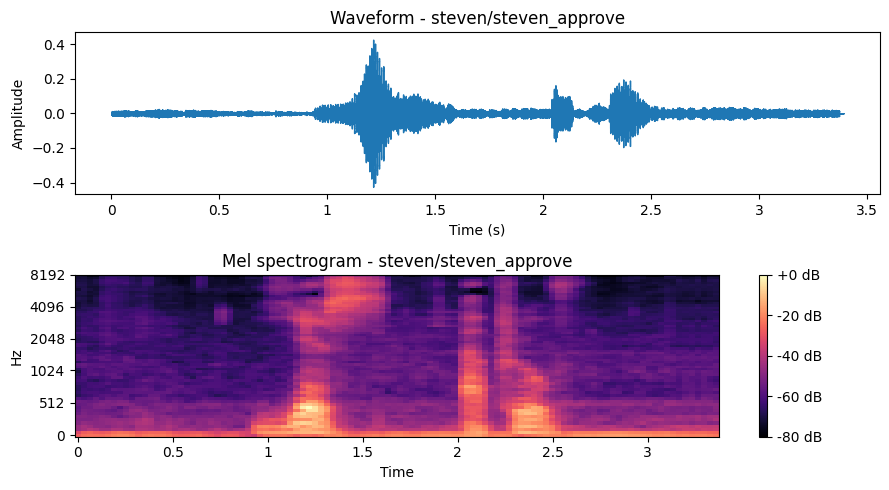

steven/steven_confirm


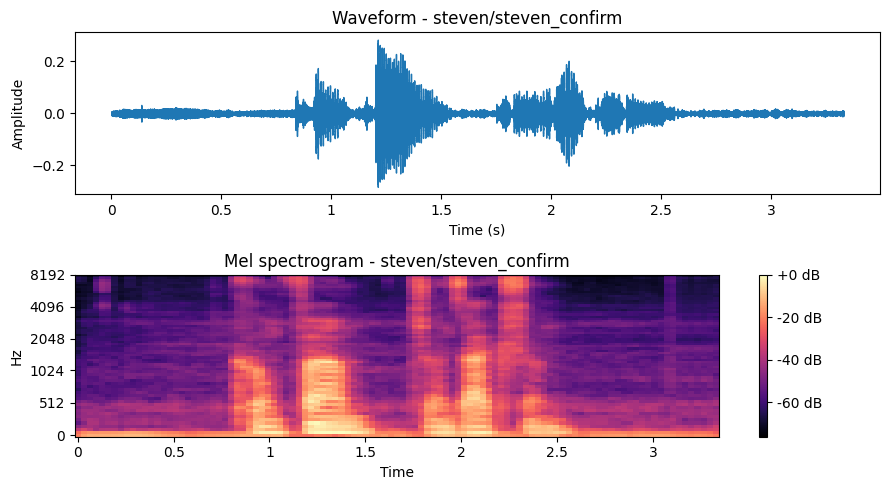

In [ ]:
for s in samples:
    y = load_audio(s['path'])
    print(s['recording_id'])
    ipd.display(ipd.Audio(y, rate=SR))
    _ = plot_waveform_spectrogram(y, s['recording_id'])
    plt.show()

## 9. Augmentations demo

/tmp/ipykernel_7869/1294308.py:25: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


pitch_up


pitch_down


time_stretch_fast


time_stretch_slow


noise


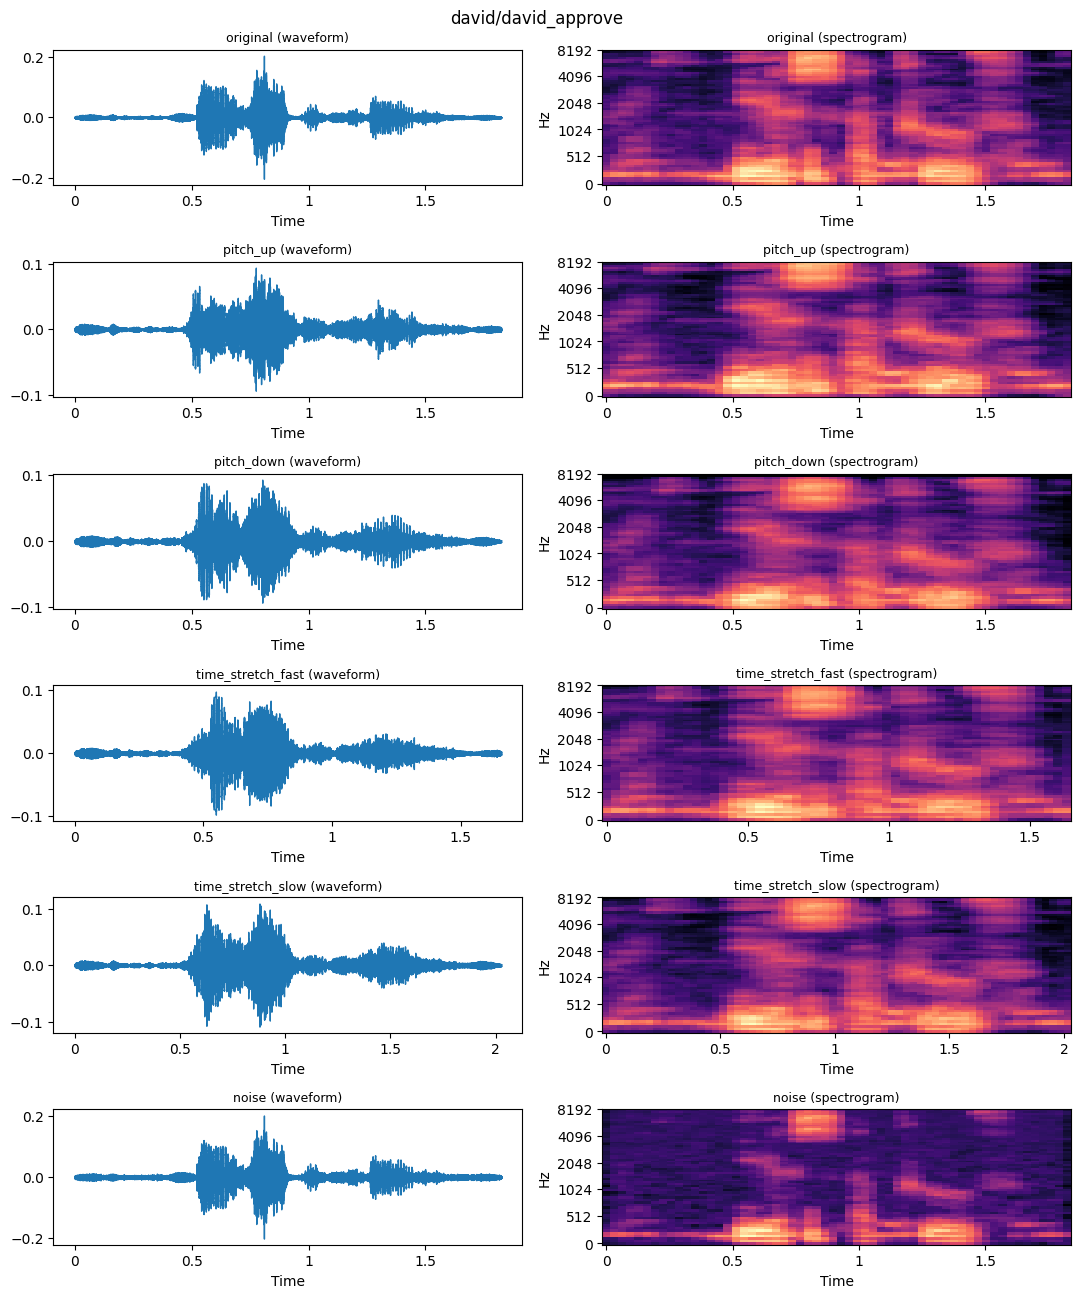

In [ ]:
y = load_audio(samples[0]['path'])
aug = augment_all(y)

for name, sig in aug.items():
    print(name)
    ipd.display(ipd.Audio(sig, rate=SR))

_ = plot_augmentation_comparison(y, aug, samples[0]['recording_id'])
plt.show()

## 10. Extract and save features

In [ ]:
df = run_pipeline(AUDIO_DIR, OUT_DIR)
df.head()

Found 8 recordings from 4 member(s)


/tmp/ipykernel_7869/3606697766.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
/tmp/ipykernel_7869/3606697766.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
/tmp/ipykernel_7869/3606697766.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(path, sr=sr, mono=True)
/usr/local/lib/python3.13/dist-packa

Saved 24 rows x 35 features -> /content/drive/MyDrive/Formative 2 ML_pipeline_Data_Collection/outputs/audio_features.csv


,member,phrase,recording_id,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_13_std,rolloff_mean,rolloff_std,rms_mean,rms_std,energy_total,centroid_mean,bandwidth_mean,zcr_mean,duration_s
0,david,approve,david/david_approve,original,-441.523773,100.305054,67.240059,56.326836,46.986546,36.905384,...,10.944789,4504.175647,2176.412313,0.014136,0.013263,11.160183,2396.356831,2044.979698,0.196095,1.824000
1,david,approve,david/david_approve,time_stretch,-452.242737,91.126007,64.238274,47.001118,49.149532,35.314140,...,10.004458,5019.981971,1849.071026,0.009555,0.008912,4.549544,2529.405305,2199.192172,0.204806,1.658187
2,david,approve,david/david_approve,noise,-334.618711,43.988419,27.900979,35.107607,32.065184,27.877982,...,6.593546,6101.293103,970.220751,0.014428,0.013083,11.267762,3222.119297,2363.208740,0.258065,1.824000
3,david,confirm,david/david_confirm,original,-380.123779,86.759850,116.319885,71.828209,25.800146,33.711887,...,9.645528,3347.656250,2401.614031,0.016139,0.008285,7.751568,1847.653130,1685.798323,0.160411,1.440000
4,david,confirm,david/david_confirm,time_stretch,-381.416687,75.619354,110.728775,56.662880,30.442734,22.159836,...,8.158536,3861.089939,2228.942761,0.012371,0.005372,3.820323,1859.069679,1868.671418,0.152558,1.309063


## 11. Voiceprint model functions

In [ ]:
import argparse
import json
import os

import joblib
import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay, f1_score, log_loss)
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


DEFAULT_THRESHOLD = 0.60  


def candidate_models():
    return {
        "logistic_regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
        "random_forest": make_pipeline(
            StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=42)),
    }


def cross_validate(model, X, y, groups, is_original, classes):
    """
    Leave-one-recording-out CV (right for tiny datasets): all augmented copies of one recording stay in the same fold, so the model
    is never tested on a pitch-shifted copy of something it trained on (that would leak).
    Train on originals + augmentations, test only on the original held-out recordings.
    """
    all_true, all_pred, all_proba = [], [], []
    for tr, te in LeaveOneGroupOut().split(X, y, groups):
        te = te[is_original[te]]
        if len(te) == 0:
            continue
        m = _clone(model).fit(X[tr], y[tr])
        proba = m.predict_proba(X[te])
        full = np.zeros((len(te), len(classes)))
        for j, c in enumerate(m.classes_):
            full[:, list(classes).index(c)] = proba[:, j]
        all_proba.append(full)
        all_true.extend(y[te])
        all_pred.extend(np.array(classes)[full.argmax(1)])
    proba = np.vstack(all_proba)
    return np.array(all_true), np.array(all_pred), proba


def _clone(model):
    from sklearn.base import clone
    return clone(model)


def train(csv_path, model_out, threshold=DEFAULT_THRESHOLD, report_dir="outputs"):
    df = pd.read_csv(csv_path)
    cols = feature_columns(df)
    X = df[cols].values
    y = df["member"].values
    groups = df["recording_id"].values
    is_original = (df["augmentation"] == "original").values
    classes = sorted(np.unique(y))
    print(f"{len(df)} rows | {len(cols)} features | members: {classes}")

    results, best_name, best_f1 = {}, None, -1
    for name, model in candidate_models().items():
        yt, yp, proba = cross_validate(model, X, y, groups, is_original, classes)
        res = {
            "accuracy": accuracy_score(yt, yp),
            "f1_macro": f1_score(yt, yp, average="macro"),
            "log_loss": log_loss(yt, proba, labels=classes),
        }
        results[name] = res
        print(f"{name:20s} acc={res['accuracy']:.3f}  f1={res['f1_macro']:.3f}  loss={res['log_loss']:.3f}")
        if res["f1_macro"] > best_f1 or (res["f1_macro"] == best_f1 and res["log_loss"] < results[best_name]["log_loss"]):
            best_name, best_f1, best_cm = name, res["f1_macro"], (yt, yp)

    print(f"Best model: {best_name}")
    os.makedirs(report_dir, exist_ok=True)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(best_cm[0], best_cm[1], labels=classes, ax=ax, colorbar=False)
    ax.set_title(f"Voiceprint CV confusion matrix ({best_name})")
    fig.tight_layout()
    fig.savefig(os.path.join(report_dir, "voiceprint_confusion_matrix.png"), dpi=120)
    plt.close(fig)
    with open(os.path.join(report_dir, "voiceprint_metrics.json"), "w") as f:
        json.dump({"cv_results": results, "best": best_name}, f, indent=2)

    final = candidate_models()[best_name].fit(X, y)  # refit on all data
    os.makedirs(os.path.dirname(model_out) or ".", exist_ok=True)
    joblib.dump({"model": final, "feature_cols": cols, "classes": classes,
                 "threshold": threshold, "name": best_name}, model_out)
    print(f"Saved model -> {model_out}")


def verify_voice(audio_path, model_path, claimed_member=None, threshold=None):
    """
    Returns dict: approved (bool), predicted_member, confidence.
    Approved only if the best-matching enrolled member has confidence >= threshold
    (and matches claimed_member when given, e.g. the user the face model identified).
    """
    bundle = joblib.load(model_path)
    threshold = bundle["threshold"] if threshold is None else threshold
    y = load_audio(audio_path)
    feats = extract_features(y)
    x = np.array([[feats[c] for c in bundle["feature_cols"]]])
    proba = bundle["model"].predict_proba(x)[0]
    classes = list(bundle["model"].classes_)
    i = int(np.argmax(proba))
    predicted, conf = classes[i], float(proba[i])
    approved = conf >= threshold and (claimed_member is None or predicted == claimed_member.lower())
    return {"approved": bool(approved), "predicted_member": predicted,
            "confidence": round(conf, 3), "threshold": threshold}

## 12. Train and evaluate(accuracy, F1, loss)

24 rows | 35 features | members: ['david', 'faith', 'honette', 'steven']
logistic_regression  acc=0.875  f1=0.867  loss=0.549
random_forest        acc=0.625  f1=0.617  loss=0.850
Best model: logistic_regression
Saved model -> /content/drive/MyDrive/Formative 2 ML_pipeline_Data_Collection/outputs/voiceprint_model.joblib
{
  "cv_results": {
    "logistic_regression": {
      "accuracy": 0.875,
      "f1_macro": 0.8666666666666667,
      "log_loss": 0.5487745477350323
    },
    "random_forest": {
      "accuracy": 0.625,
      "f1_macro": 0.6166666666666667,
      "log_loss": 0.8499447271610161
    }
  },
  "best": "logistic_regression"
}


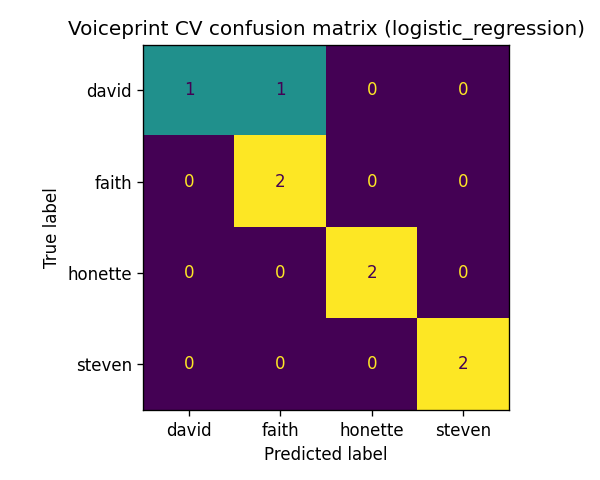

In [ ]:
import json
train(f'{OUT_DIR}/audio_features.csv', f'{OUT_DIR}/voiceprint_model.joblib', report_dir=OUT_DIR)

print(json.dumps(json.load(open(f'{OUT_DIR}/voiceprint_metrics.json')), indent=2))
ipd.Image(f'{OUT_DIR}/voiceprint_confusion_matrix.png')